In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, hamming_loss, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             multilabel_confusion_matrix)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

desc = pd.read_csv("mixed_desc.csv")
ecfp = pd.read_csv("mixed_ecfp.csv")
fcfp = pd.read_csv("mixed_fcfp.csv")

ID_COL = "CIDs"
TARGET = "EC1_EC2_EC3_EC4_EC5_EC6"
LABEL_COLS = ["EC1", "EC2", "EC3", "EC4", "EC5", "EC6"]

# Label diambil dari file mana? "desc" (disarankan, lihat Sel 3) atau "ecfp"
LABEL_SOURCE = "desc"

print("desc:", desc.shape, "| ecfp:", ecfp.shape, "| fcfp:", fcfp.shape)
display(desc[[ID_COL, TARGET]].head())

desc: (1039, 198) | ecfp: (1039, 514) | fcfp: (1039, 514)


,CIDs,EC1_EC2_EC3_EC4_EC5_EC6
0,C00009,1_1_1_1_0_1
1,C00013,1_1_1_1_0_1
2,C00014,1_1_1_1_0_1
3,C00017,0_1_1_0_0_0
4,C00022,1_1_1_1_0_1


In [2]:
print("CIDs identik di ketiga file:", (desc[ID_COL] == ecfp[ID_COL]).all() and (desc[ID_COL] == fcfp[ID_COL]).all())
print("CIDs unik:", desc[ID_COL].is_unique)

for nama, d in [("desc", desc), ("ecfp", ecfp), ("fcfp", fcfp)]:
    fitur = d.drop(columns=[ID_COL, TARGET])
    print(f"{nama}: fitur={fitur.shape[1]}, missing={d.isna().sum().sum()}, "
          f"duplikat={d.duplicated().sum()}, kolom konstan={(fitur.nunique() <= 1).sum()}")

print("\nNilai unik fitur ecfp:", sorted(set(ecfp.drop(columns=[ID_COL, TARGET]).values.ravel())))
print("Nilai unik fitur fcfp:", sorted(set(fcfp.drop(columns=[ID_COL, TARGET]).values.ravel())))

# Kolom dengan rentang paling ekstrem pada desc
besar = desc.drop(columns=[ID_COL, TARGET]).abs().max().sort_values(ascending=False).head(3)
print("\nKolom desc dengan nilai maksimum terbesar:")
display(besar.to_frame("nilai_maks"))

CIDs identik di ketiga file: True
CIDs unik: True
desc: fitur=196, missing=0, duplikat=0, kolom konstan=27
ecfp: fitur=512, missing=0, duplikat=0, kolom konstan=1
fcfp: fitur=512, missing=0, duplikat=0, kolom konstan=4

Nilai unik fitur ecfp: [np.int64(0), np.int64(1)]
Nilai unik fitur fcfp: [np.int64(0), np.int64(1)]

Kolom desc dengan nilai maksimum terbesar:


,nilai_maks
Ipc,3.600000e+50
BertzCT,4.069960e+03
MolWt,2.238749e+03


In [3]:
def pecah_label(seri):
    """Ubah teks '1_1_0_1_0_0' menjadi tabel 6 kolom 0/1."""
    return pd.DataFrame([[int(x) for x in s.split("_")] for s in seri],
                        columns=LABEL_COLS, index=seri.index)

Y_desc = pecah_label(desc[TARGET])
Y_ecfp = pecah_label(ecfp[TARGET])
Y_fcfp = pecah_label(fcfp[TARGET])

beda = (Y_desc != Y_ecfp).any(axis=1)
print("Baris dengan label desc != ecfp :", beda.sum(), "dari", len(desc))
print("Baris dengan label ecfp != fcfp :", (Y_ecfp != Y_fcfp).any(axis=1).sum())
print("Indeks baris pertama yang berbeda:", beda.idxmax(), "| terakhir:", beda[beda].index.max())
print("Baris 0-490 identik:", not beda[:491].any())

display(pd.DataFrame({"CID": desc[ID_COL][beda],
                      "label_desc": desc[TARGET][beda],
                      "label_ecfp": ecfp[TARGET][beda]}).head(8))

print("\nRata-rata label per senyawa pada baris 491 ke atas:")
print("  desc:", round(Y_desc.iloc[491:].sum(axis=1).mean(), 2),
      "| ecfp:", round(Y_ecfp.iloc[491:].sum(axis=1).mean(), 2))

Baris dengan label desc != ecfp : 506 dari 1039
Baris dengan label ecfp != fcfp : 0
Indeks baris pertama yang berbeda: 491 | terakhir: 1038
Baris 0-490 identik: True


,CID,label_desc,label_ecfp
491,C01326,0_0_1_1_0_0,1_0_0_0_0_0
492,C01327,1_1_0_0_1_0,0_0_1_1_0_0
493,C01344,0_1_1_0_0_0,0_0_0_1_0_0
494,C01346,1_1_0_0_0_0,0_0_1_0_0_0
495,C01384,0_0_1_0_1_0,1_0_0_0_0_0
496,C01424,1_1_0_1_0_0,1_0_0_0_0_0
497,C01444,0_1_1_0_0_0,0_1_0_0_0_0
498,C01455,1_0_0_1_0_0,1_0_0_0_0_0



Rata-rata label per senyawa pada baris 491 ke atas:
  desc: 2.14 | ecfp: 1.23


In [4]:
# Uji: label mana yang lebih konsisten dengan fitur? (fitur sama = ecfp)
cv_uji = KFold(n_splits=5, shuffle=True, random_state=42)
X_uji = ecfp.drop(columns=[ID_COL, TARGET]).values

for nama, Y_ in [("label dari desc", Y_desc), ("label dari ecfp", Y_ecfp)]:
    P = cross_val_predict(RandomForestClassifier(300, random_state=42, n_jobs=-1),
                          X_uji, Y_.values, cv=cv_uji)
    print(f"Fitur ecfp + {nama}: F1 micro = {f1_score(Y_, P, average='micro'):.3f}")

Y = Y_desc if LABEL_SOURCE == "desc" else Y_ecfp
print("\nLabel yang dipakai:", LABEL_SOURCE)

Fitur ecfp + label dari desc: F1 micro = 0.733
Fitur ecfp + label dari ecfp: F1 micro = 0.560

Label yang dipakai: desc


In [5]:
jumlah_label = Y.sum(axis=1)
kardinalitas = jumlah_label.mean()
densitas = kardinalitas / Y.shape[1]

print(f"Label cardinality : {kardinalitas:.3f} (rata-rata label per senyawa)")
print(f"Label density     : {densitas:.3f}")
print(f"Senyawa tanpa label aktif: {(jumlah_label == 0).sum()}")
print(f"Senyawa dengan >1 label  : {(jumlah_label > 1).sum()} ({(jumlah_label > 1).mean()*100:.1f}%)")
print(f"Kombinasi label unik     : {Y.astype(str).agg(''.join, axis=1).nunique()}")

per_label = pd.DataFrame({"jumlah_positif": Y.sum(),
                          "persen": (Y.mean() * 100).round(1)}).sort_values("jumlah_positif", ascending=False)
display(per_label)

Label cardinality : 2.392 (rata-rata label per senyawa)
Label density     : 0.399
Senyawa tanpa label aktif: 0
Senyawa dengan >1 label  : 1039 (100.0%)
Kombinasi label unik     : 47


,jumlah_positif,persen
EC2,781,75.2
EC1,656,63.1
EC3,388,37.3
EC4,326,31.4
EC5,177,17.0
EC6,157,15.1


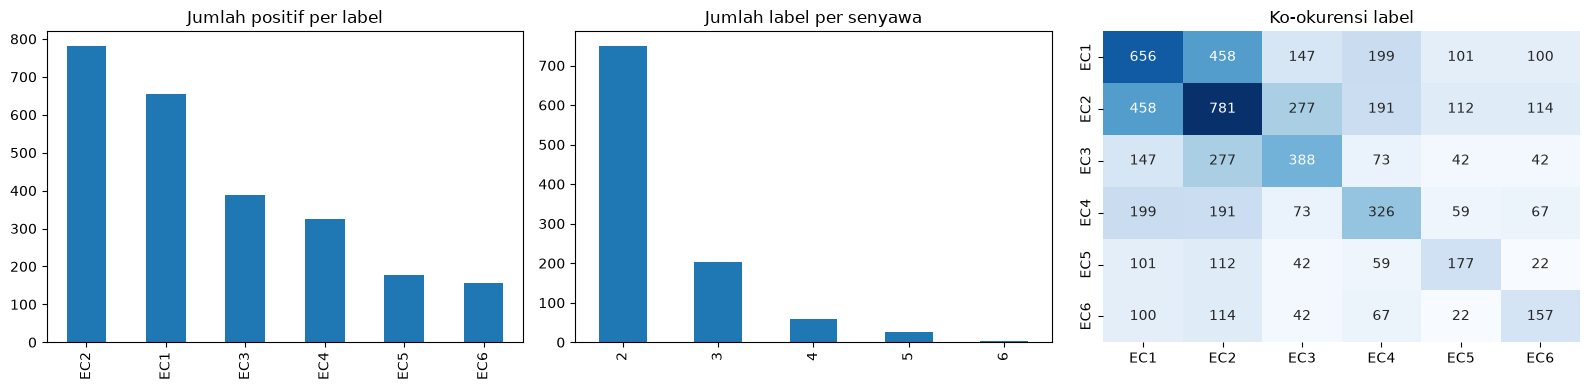

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
per_label["jumlah_positif"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Jumlah positif per label")
jumlah_label.value_counts().sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Jumlah label per senyawa")
sns.heatmap(Y.T.dot(Y), annot=True, fmt="d", cmap="Blues", ax=axes[2], cbar=False)
axes[2].set_title("Ko-okurensi label")
plt.tight_layout()
plt.show()

In [7]:
def siapkan(d, log_cols=()):
    X = d.drop(columns=[ID_COL, TARGET]).astype(float)
    for c in log_cols:
        X[c] = np.log1p(X[c])          # meredam nilai ekstrem
    return X.loc[:, X.nunique() > 1]   # buang kolom konstan

feature_sets = {
    "desc": siapkan(desc, log_cols=["Ipc"]),
    "ecfp": siapkan(ecfp),
    "fcfp": siapkan(fcfp),
}
for nama, X_ in feature_sets.items():
    print(f"{nama}: {X_.shape[1]} fitur")

# Satu pembagian yang sama untuk ketiga set fitur
idx_train, idx_test = train_test_split(np.arange(len(Y)), test_size=0.2, random_state=42)
Y_train, Y_test = Y.iloc[idx_train], Y.iloc[idx_test]
print("Train:", len(idx_train), "| Test:", len(idx_test))
display(pd.DataFrame({"positif_train": Y_train.sum(), "positif_test": Y_test.sum()}))

desc: 169 fitur
ecfp: 511 fitur
fcfp: 508 fitur
Train: 831 | Test: 208


,positif_train,positif_test
EC1,533,123
EC2,624,157
EC3,305,83
EC4,249,77
EC5,142,35
EC6,128,29


In [8]:
def buat_models():
    return {
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
        "Logistic Regression (balanced)": Pipeline([
            ("sc", StandardScaler()),
            ("clf", OneVsRestClassifier(LogisticRegression(max_iter=3000, class_weight="balanced", C=0.1)))]),
        "KNN": KNeighborsClassifier(n_neighbors=5),
    }

def hitung_metrik(Y_asli, Y_pred):
    return {
        "Subset accuracy": accuracy_score(Y_asli, Y_pred),
        "Hamming loss": hamming_loss(Y_asli, Y_pred),
        "F1 (micro)": f1_score(Y_asli, Y_pred, average="micro", zero_division=0),
        "F1 (macro)": f1_score(Y_asli, Y_pred, average="macro", zero_division=0),
        "F1 (samples)": f1_score(Y_asli, Y_pred, average="samples", zero_division=0),
    }

# KFold biasa (StratifiedKFold tidak mendukung target multilabel)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for nama_fitur, X_ in feature_sets.items():
    X_tr = X_.iloc[idx_train].values
    for nama_model, model in buat_models().items():
        pred = cross_val_predict(model, X_tr, Y_train.values, cv=cv)
        rows.append({"Fitur": nama_fitur, "Model": nama_model, **hitung_metrik(Y_train.values, pred)})

hasil_cv = pd.DataFrame(rows).set_index(["Fitur", "Model"]).round(4).sort_values("F1 (macro)", ascending=False)
display(hasil_cv)
print("Pembanding tebak semua 0 -> hamming loss:", round(hamming_loss(Y_train, np.zeros_like(Y_train)), 4))

Subset accuracy  Hamming loss  F1 (micro)  F1 (macro)  F1 (samples)
Fitur Model                                                                                              
fcfp  Logistic Regression (balanced)           0.2575        0.2437      0.7037      0.6354        0.7027
      Random Forest                            0.3538        0.2036      0.7426      0.6262        0.7456
ecfp  Logistic Regression (balanced)           0.2383        0.2557      0.6850      0.6202        0.6797
      Random Forest                            0.3622        0.2054      0.7370      0.6193        0.7405
desc  Logistic Regression (balanced)           0.1781        0.2852      0.6572      0.6154        0.6507
      Random Forest                            0.3610        0.2040      0.7373      0.6093        0.7398
fcfp  KNN                                      0.2744        0.2325      0.7119      0.6047        0.7137
ecfp  KNN                                      0.2744        0.2425      0.7049      0.5875        0.7090
desc  KNN                                      0.2395        0.2569      0.6740      0.5342        0.6677

Pembanding tebak semua 0 -> hamming loss: 0.3973


In [9]:
def proba_matrix(model, X_):
    p = model.predict_proba(X_)
    if isinstance(p, list):
        return np.column_stack([a[:, 1] for a in p])
    return p

rows, fitted = [], {}
for nama_fitur, X_ in feature_sets.items():
    X_tr, X_te = X_.iloc[idx_train].values, X_.iloc[idx_test].values
    for nama_model, model in buat_models().items():
        model.fit(X_tr, Y_train.values)
        pred = model.predict(X_te)
        fitted[(nama_fitur, nama_model)] = model
        rows.append({"Fitur": nama_fitur, "Model": nama_model,
                     **hitung_metrik(Y_test.values, pred),
                     "ROC-AUC (macro)": roc_auc_score(Y_test.values, proba_matrix(model, X_te), average="macro")})

hasil_test = pd.DataFrame(rows).set_index(["Fitur", "Model"]).round(4).sort_values("F1 (macro)", ascending=False)
display(hasil_test)

,,Subset accuracy,Hamming loss,F1 (micro),F1 (macro),F1 (samples),ROC-AUC (macro)
Fitur,Model,,,,,,
fcfp,Logistic Regression (balanced),0.2260,0.2804,0.6609,0.5967,0.6436,0.7237
desc,Random Forest,0.3365,0.2115,0.7261,0.5933,0.7246,0.7614
fcfp,Random Forest,0.3029,0.2244,0.7177,0.5908,0.7190,0.7791
ecfp,Logistic Regression (balanced),0.2260,0.2796,0.6673,0.5905,0.6593,0.7339
fcfp,KNN,0.2500,0.2484,0.6949,0.5888,0.6919,0.7399
ecfp,KNN,0.2452,0.2644,0.6833,0.5850,0.6807,0.7244
desc,Logistic Regression (balanced),0.1635,0.3141,0.6267,0.5817,0.6099,0.7273
ecfp,Random Forest,0.2981,0.2316,0.7054,0.5599,0.7041,0.7718
desc,KNN,0.1635,0.2829,0.6431,0.5275,0.6312,0.6497


Kombinasi terbaik (menurut CV): fcfp + Logistic Regression (balanced)
              precision    recall  f1-score   support

         EC1       0.71      0.73      0.72       123
         EC2       0.80      0.73      0.76       157
         EC3       0.67      0.69      0.68        83
         EC4       0.59      0.57      0.58        77
         EC5       0.42      0.69      0.52        35
         EC6       0.26      0.38      0.31        29

   micro avg       0.65      0.68      0.66       504
   macro avg       0.58      0.63      0.60       504
weighted avg       0.67      0.68      0.67       504
 samples avg       0.64      0.68      0.64       504



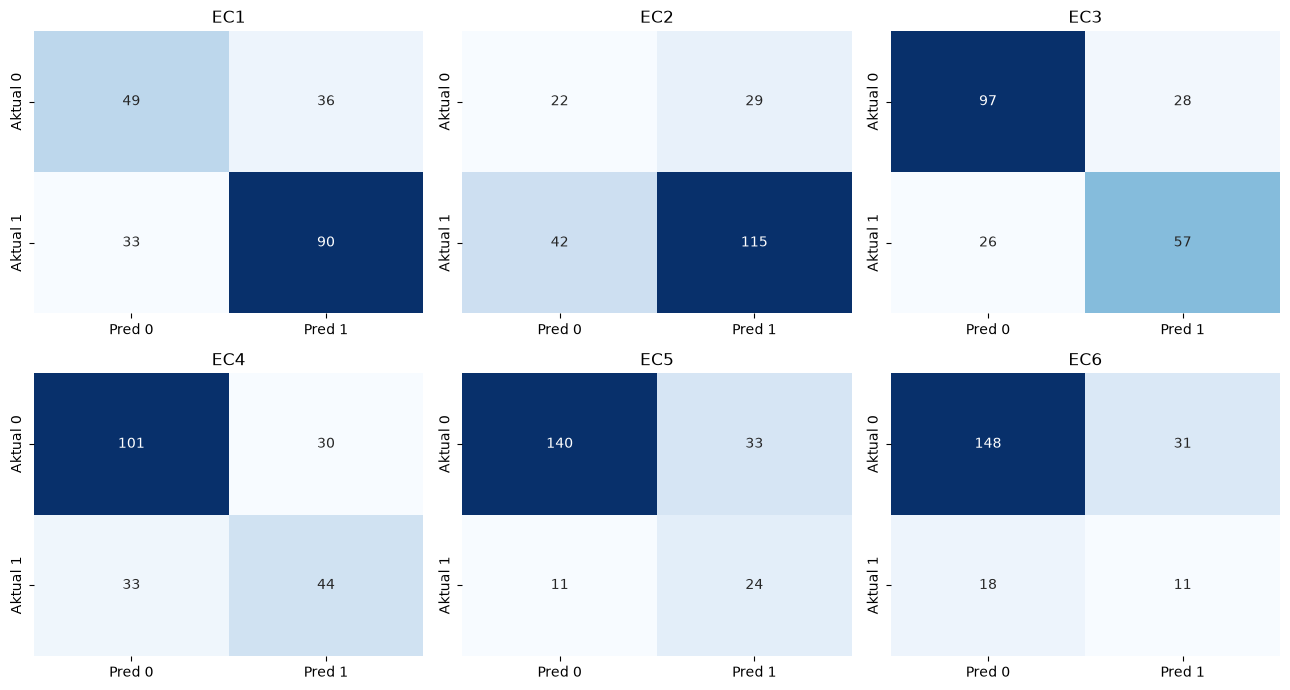

In [10]:
kunci_terbaik = hasil_cv.index[0]                 # dipilih berdasarkan cross-validation
nama_fitur, nama_model = kunci_terbaik
terbaik = fitted[kunci_terbaik]
X_te = feature_sets[nama_fitur].iloc[idx_test].values
pred = terbaik.predict(X_te)

print("Kombinasi terbaik (menurut CV):", nama_fitur, "+", nama_model)
print(classification_report(Y_test.values, pred, target_names=LABEL_COLS, zero_division=0))

mcm = multilabel_confusion_matrix(Y_test.values, pred)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, m, nama in zip(axes.ravel(), mcm, LABEL_COLS):
    sns.heatmap(m, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["Aktual 0", "Aktual 1"])
    ax.set_title(nama)
plt.tight_layout()
plt.show()

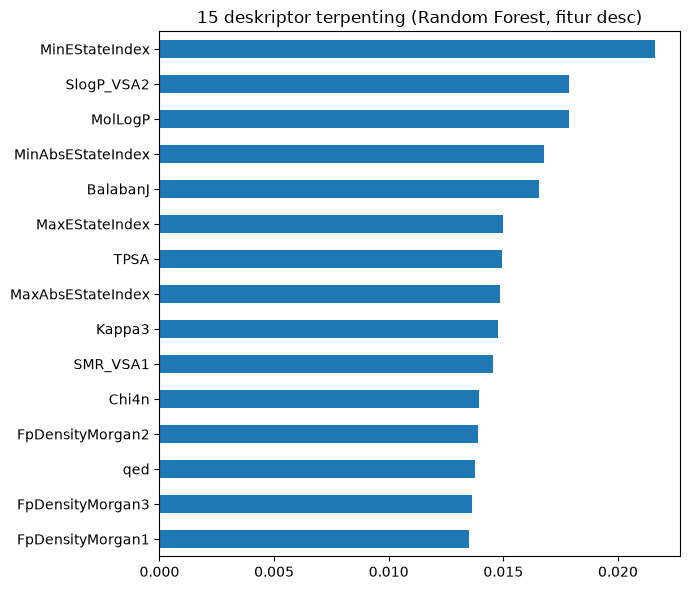

Model tersimpan: model_mixed.pkl


In [11]:
import joblib

rf_desc = fitted[("desc", "Random Forest")]
penting = pd.Series(rf_desc.feature_importances_, index=feature_sets["desc"].columns).sort_values()

plt.figure(figsize=(7, 6))
penting.tail(15).plot(kind="barh")
plt.title("15 deskriptor terpenting (Random Forest, fitur desc)")
plt.tight_layout()
plt.show()

joblib.dump({"model": terbaik, "fitur": nama_fitur, "label": LABEL_COLS}, "model_mixed.pkl")
print("Model tersimpan: model_mixed.pkl")

# README: Dataset Mixed (Klasifikasi Multilabel)

## Ringkasan dataset

| Item | Keterangan |
|---|---|
| File | `mixed_desc.csv`, `mixed_ecfp.csv`, `mixed_fcfp.csv` |
| Jumlah data | 1.039 senyawa (baris) pada setiap file |
| ID | `CIDs` (misalnya `C00009`), identik dan berurutan sama di ketiga file |
| Fitur | `desc`: 196 deskriptor kimia (numerik). `ecfp`: 512 bit sidik jari (0/1). `fcfp`: 512 bit sidik jari (0/1) |
| Target | `EC1_EC2_EC3_EC4_EC5_EC6` berisi teks seperti `1_1_0_1_0_0`, yaitu 6 label yang digabung dengan garis bawah |
| Missing value | Tidak ada |
| Duplikat | Tidak ada |

Ketiga file adalah tiga representasi fitur untuk senyawa yang sama. Nama label EC1-EC6 kemungkinan merujuk ke enam kelas utama enzim, tetapi file ini tidak menjelaskannya.

## Mengapa ini termasuk klasifikasi multilabel

1. **Pembelajaran terawasi (supervised).** Setiap senyawa sudah punya label pada kolom target.
2. **Targetnya berupa beberapa kolom biner.** Teks `1_1_0_1_0_0` dipecah menjadi 6 label, masing-masing bernilai 0 atau 1. Targetnya bukan satu kelas, melainkan vektor 6 angka 0/1.
3. **Satu senyawa boleh punya beberapa label sekaligus.** Rata-rata ada 2,39 label aktif per senyawa, dan tidak ada senyawa yang tanpa label.
4. **Label tidak saling lepas.** Inilah pembeda utama dari klasifikasi multikelas. Pada multikelas, satu data hanya masuk ke tepat satu kelas. Di sini, sebuah senyawa bisa terkait dengan beberapa kelas enzim sekaligus, dengan 47 kombinasi label berbeda.
5. **Keluaran model berupa himpunan label.** Model memprediksi kelas mana saja yang aktif untuk sebuah senyawa.

| Label | Jumlah positif | Persentase |
|---|---|---|
| EC2 | 781 | 75,2% |
| EC1 | 656 | 63,1% |
| EC3 | 388 | 37,3% |
| EC4 | 326 | 31,4% |
| EC5 | 177 | 17,0% |
| EC6 | 157 | 15,1% |

Statistik di atas memakai label dari `mixed_desc.csv`. Label cardinality adalah 2,39 dan label density 0,40.

## Karakteristik penting

- **Label tidak konsisten antar file.** Pada baris 0-490, label di ketiga file identik. Pada baris 491-1038, label `mixed_desc.csv` berbeda dari `mixed_ecfp.csv` di 506 baris, sedangkan label `mixed_ecfp.csv` dan `mixed_fcfp.csv` identik satu sama lain.
- **Petunjuk bahwa label `desc` lebih konsisten.** Fitur ECFP memprediksi label `desc` jauh lebih baik (F1 micro 0,734) daripada label `ecfp` sendiri (0,560). Pada baris 0-490, fitur `desc` dan `ecfp` hasilnya hampir sama. Ini inferensi dari data, bukan bukti, dan sebaiknya dikonfirmasi ke sumber dataset. Notebook memakai label dari `mixed_desc.csv` untuk ketiga set fitur.
- **Pembersihan data:** kolom konstan dibuang (tersisa 169 fitur `desc`, 511 fitur `ecfp`, 508 fitur `fcfp`). Kolom `Ipc` bernilai sangat ekstrem (sampai 3,6 x 10^50), sehingga diubah dengan `log1p`.
- **Pembagian data** memakai `KFold` biasa, karena `StratifiedKFold` dan `stratify=` tidak mendukung target multilabel.

## Hasil baseline (5-fold cross-validation, label dari `mixed_desc.csv`)

| Fitur | Model | Hamming loss | F1 micro | F1 macro |
|---|---|---|---|---|
| desc | Random Forest | 0,201 | 0,743 | 0,613 |
| fcfp | Random Forest | 0,205 | 0,742 | 0,614 |
| ecfp | Random Forest | 0,209 | 0,734 | 0,600 |
| fcfp | KNN | 0,232 | 0,714 | 0,610 |
| ecfp | KNN | 0,244 | 0,704 | 0,594 |
| fcfp | Logistic Regression (balanced) | 0,251 | 0,697 | 0,633 |
| ecfp | Logistic Regression (balanced) | 0,256 | 0,690 | 0,622 |
| desc | KNN | 0,263 | 0,665 | 0,535 |
| desc | Logistic Regression (balanced) | 0,293 | 0,652 | 0,610 |

Pembanding menebak semua 0 memberi hamming loss 0,399. Selisih antar set fitur untuk Random Forest sangat kecil, sehingga tidak bisa disimpulkan satu representasi pasti lebih baik. Label jarang (EC5 dan EC6) lebih sulit, terlihat dari F1 macro (sekitar 0,61) yang lebih rendah daripada F1 micro (sekitar 0,74).

## LINK DATASET

(Multi-label Classification of Enzyme Substrates) [https://www.kaggle.com/datasets/gopalns/ec-mixed-class]